# Эксперимент с обещанием доставки за 40 минут

В пешей зоне доля заказов снизилась на 3,62 п.п. Опозданий среди оформленных заказов во всём эксперименте стало меньше на 13,1 п.п. Диапазон возможного изменения выручки включает потери больше допустимых 10 ₽ на сессию. По заранее принятому правилу нужно продлить тест.

## 1. Условия эксперимента

С 1 по 21 декабря в группе B гостям на расстоянии меньше 2 км показывали обещание 40 минут, в A — 30. Единица записи — сессия. Смотрю на опоздания среди оформленных заказов, конверсию, отзывы и выручку на все сессии. Для внедрения нужны значимое снижение опозданий и нижняя граница 95 % ДИ разницы выручки выше −10 ₽.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multitest import multipletests
RANDOM_STATE=0

In [2]:
ab=pd.read_csv(Path("../data/ab_promise.csv"),parse_dates=["ts"])
srm_p=stats.chisquare(ab.groupby("group").size()).pvalue
short=ab[ab.distance_km<2]
promise_ok=(short.loc[short.group=="A","promise_min"]==30).all() and (short.loc[short.group=="B","promise_min"]==40).all()
far=ab[ab.distance_km>=2]
far_same=set(far.loc[far.group=="A","promise_min"])==set(far.loc[far.group=="B","promise_min"])
orders=ab.loc[ab.ordered==1].copy()
assert ab.session_id.is_unique
print(ab.groupby("group").size(), srm_p, promise_ok, far_same)
print(ab.loc[ab.distance_km==2].groupby(["group","promise_min"]).size())

group
A    3924
B    3971
dtype: int64 0.5968340779632235 True True
group  promise_min
A      45             148
B      45             112
dtype: int64


В A 3 924 сессии, в B 3 971, p SRM = 0,597. Обещания в ближней зоне соответствуют заданию, в дальней набор значений совпадает. Все 260 сессий на расстоянии 2,0 км получили 45 минут. В таблице есть session_id, но нет гостевого ключа, поэтому закрепление гостя за одной группой при повторных визитах проверить не удалось.

## 2. Главное обещание и конверсия

In [3]:
g=orders.groupby("group")["late"]
a,b=g.mean()
n,m=g.size()
p=proportions_ztest(g.sum(),g.size())[1]
late_a,late_b=round(a,4),round(b,4)
diff_pp=round(100*(b-a),1)
w=196*np.sqrt(a*(1-a)/n+b*(1-b)/m)
ci=tuple(np.round([100*(b-a)-w,100*(b-a)+w],1))
p_late=p
print(late_a,late_b,diff_pp,ci,p_late)

0.2652 0.1345 -13.1 (np.float64(-16.1), np.float64(-10.1)) 4.096761840572387e-17


In [4]:
def conversion(v):
    g=v.groupby("group").ordered
    a,b=g.mean()
    return proportions_ztest(g.sum(),g.size())[1],round(100*(b-a),2)
p_all,d_all=conversion(ab)
p_short,d_short=conversion(ab[ab.distance_km<2])
p_far,d_far=conversion(ab[ab.distance_km>=2])
print([(d_all,p_all),(d_short,p_short),(d_far,p_far)])

[(-2.02, np.float64(0.057329715801903526)), (-3.62, np.float64(0.04648689047486339)), (-1.19, np.float64(0.36302605338283767))]


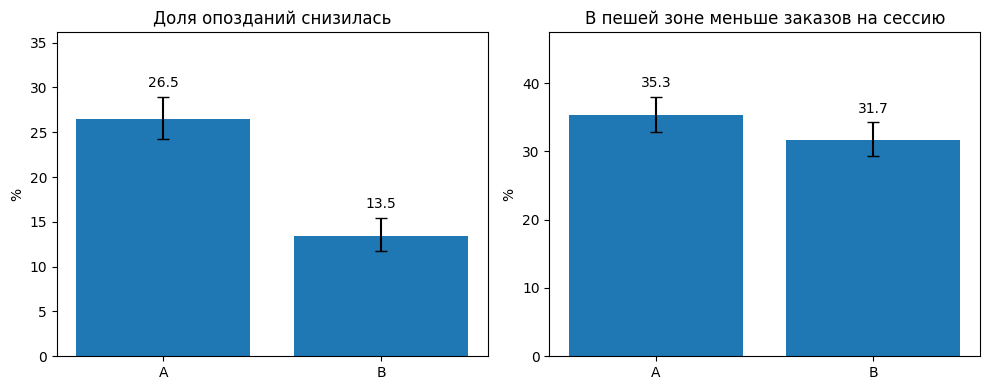

In [5]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,v,col,title in zip(axes,[orders,ab[ab.distance_km<2]],["late","ordered"],["Доля опозданий снизилась","В пешей зоне меньше заказов на сессию"]):
    g=v.groupby("group")[col]
    pct=g.mean()*100
    lo,hi=proportion_confint(g.sum(),g.size(),method="wilson")
    bars=ax.bar(pct.index,pct,yerr=[pct-lo*100,hi*100-pct],capsize=4)
    ax.bar_label(bars,labels=[f"{x:.1f}" for x in pct],padding=5)
    ax.set_ylabel("%")
    ax.set_title(title)
    ax.set_ylim(0,max(hi)*125)
fig.tight_layout()
plt.show()

Среди состоявшихся заказов опоздали 26,5 % в контроле и 13,5 % в варианте B. Разница −13,1 п.п., ДИ около −16,1…−10,1 п.п. Метрика оценивает выполнение показанного обещания. Эффект на конверсию среди всех сессий −2,02 п.п. (p = 0,057), на ближних маршрутах −3,62 п.п. (p = 0,046), на дальних −1,19 п.п. (p = 0,363). Изменение метрики опозданий само по себе не говорит, насколько изменилась фактическая скорость доставки.

## 3. Оценки гостей и города

In [6]:
r=orders.dropna(subset=["rating"])
a,b=r.rating[r.group=="A"],r.rating[r.group=="B"]
rating_a,rating_b=round(a.mean(),2),round(b.mean(),2)
low_a,low_b=round((a<=4).mean(),3),round((b<=4).mean(),3)
p_rating=stats.mannwhitneyu(a,b).pvalue
print(r.groupby("group").size(),rating_a,rating_b,low_a,low_b,p_rating)

group
A    709
B    729
dtype: int64 4.46 4.64 0.362 0.269 6.96221496216511e-05


In [7]:
rows=[]
for city,v in orders.groupby("city"):
    g=v.groupby("group").late
    a,b=g.mean()
    rows.append(dict(city=city,late_a=a,late_b=b,diff_pp=100*(b-a),p=proportions_ztest(g.sum(),g.size())[1]))
by_city=pd.DataFrame(rows).set_index("city")
by_city["p_holm"]=multipletests(by_city.p,method="holm")[1]
all_cities=((by_city.p_holm<.05)&(by_city.diff_pp<0)).all()
by_city

,late_a,late_b,diff_pp,p,p_holm
city,,,,,
Казань,0.253363,0.140590,-11.277366,0.000024,0.000049
Пермь,0.259259,0.155136,-10.412299,0.000068,0.000068
Тюмень,0.291304,0.099476,-19.182791,0.000001,0.000005
Уфа,0.275862,0.104167,-17.169540,0.000015,0.000045


Оценки оставили для 709 и 729 заказов в A и B. Среди этих ответов средние выросли с 4,46 до 4,64, доля оценок до четырёх включительно упала с 36,2 % до 26,9 %. Во всех четырёх городах опозданий в B меньше, все сравнения значимы после поправки Холма.

## 4. Выручка на сессию

In [8]:
rng=np.random.default_rng(RANDOM_STATE)
a=ab.amount[ab.group=="A"].to_numpy()
b=ab.amount[ab.group=="B"].to_numpy()
rev_a,rev_b=round(a.mean(),1),round(b.mean(),1)
p_rev=stats.ttest_ind(b,a,equal_var=False).pvalue
boot=[rng.choice(b,len(b)).mean()-rng.choice(a,len(a)).mean() for _ in range(3000)]
rev_lo,rev_hi=np.percentile(boot,[2.5,97.5])
print(rev_a,rev_b,p_rev,rev_lo,rev_hi)

206.1 193.1 0.09928130930636497 -28.27536874597457 2.13407598982787


Снижение выручки видно в точечной оценке. Для решения сравниваю интервал разницы с допустимым порогом.

## 5. Выводы и рекомендации

In [9]:
def promise_report(ab):
    srm_ok=stats.chisquare(ab.groupby("group").size()).pvalue>=.01
    def contrast(v,col):
        g=v.groupby("group")[col]
        a,b=g.mean()
        return 100*(b-a),proportions_ztest(g.sum(),g.size())[1]
    late,lp=contrast(ab[ab.ordered==1],"late")
    conv,cp=contrast(ab[ab.distance_km<2],"ordered")
    a,b=ab.amount[ab.group=="A"],ab.amount[ab.group=="B"]
    r=b.mean()-a.mean()
    p=stats.ttest_ind(b,a,equal_var=False).pvalue
    w=1.96*np.sqrt(a.var()/len(a)+b.var()/len(b))
    lo,hi=r-w,r+w
    if not srm_ok or late>=0 or lp>=.05 or hi < -10:
        result="не внедрять"
    elif lo > -10:
        result="внедрять"
    else:
        result="продлить тест"
    return dict(srm_ok=srm_ok,late_diff_pp=round(late,1),late_p=lp,conv_short_diff_pp=round(conv,2),conv_short_p=cp,rev_diff=round(r,1),rev_p=p,rev_lo=round(lo,1),rev_hi=round(hi,1),decision=result)


report=promise_report(ab)
print(report)
print({city:promise_report(v)["decision"] for city,v in ab.groupby("city")})

{'srm_ok': np.True_, 'late_diff_pp': -13.1, 'late_p': np.float64(4.096761840572387e-17), 'conv_short_diff_pp': -3.62, 'conv_short_p': np.float64(0.04648689047486339), 'rev_diff': np.float64(-13.0), 'rev_p': np.float64(0.09928130930636497), 'rev_lo': np.float64(-28.4), 'rev_hi': np.float64(2.5), 'decision': 'продлить тест'}


{'Казань': 'продлить тест', 'Пермь': 'продлить тест', 'Тюмень': 'продлить тест', 'Уфа': 'продлить тест'}


Выручка на сессию составила 206,1 ₽ в A и 193,1 ₽ в B. Разница −13,0 ₽, p Уэлча = 0,099. Бутстрэп дал ДИ от −28,3 до +2,1 ₽, нормальное приближение из правила решения — от −28,4 до +2,5 ₽. Оба включают −10 ₽. По правилу проекта тест нужно продлить. Перед продолжением стоит зафиксировать объём дополнительной выборки, момент следующей проверки и порядок учёта повторного анализа.